In [8]:
# ==========================================
# HAZIRLIK (SETUP): KÖŞE SIRALAMA VE KAMERA MATRİSİ
# ==========================================

import cv2
import numpy as np
import urllib.request

url = "https://i.imgur.com/rLOD58k.png"
req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(req) as resp:
    arr = np.asarray(bytearray(resp.read()), dtype=np.uint8)
img_bgr = cv2.imdecode(arr, cv2.IMREAD_COLOR)

h, w = img_bgr.shape[:2]

box = np.array([
    [1109, 556],
    [955,  556],
    [955,  533],
    [1109, 533]
], dtype="float32")


def order_points(pts):
    """
    4 köşe noktasını her zaman tutarlı bir sıraya dizer:
    [Sol-Üst (TL), Sağ-Üst (TR), Sağ-Alt (BR), Sol-Alt (BL)]
    """
    rect = np.zeros((4, 2), dtype="float32")

    s = pts.sum(axis=1)
    rect[0] = pts[np.argmin(s)]
    rect[2] = pts[np.argmax(s)]
    diff = np.diff(pts, axis=1)
    rect[1] = pts[np.argmin(diff)]
    rect[3] = pts[np.argmax(diff)]
    return rect

image_points = order_points(box)

focal_length = float(w)
center_x = w / 2.0
center_y = h / 2.0

camera_matrix = np.array([
    [focal_length, 0.0,          center_x],
    [0.0,          focal_length, center_y],
    [0.0,          0.0,          1.0]], dtype="float32")

dist_coeffs = np.zeros((4, 1), dtype="float32")

print("Sıralanmış 2B Köşeler [TL, TR, BR, BL]:\n", image_points)
print("\nKamera Matrisi (K):\n", camera_matrix)
print("\nBozulma Katsayıları (D):\n", dist_coeffs)

Sıralanmış 2B Köşeler [TL, TR, BR, BL]:
 [[ 955.  533.]
 [1109.  533.]
 [1109.  556.]
 [ 955.  556.]]

Kamera Matrisi (K):
 [[1.919e+03 0.000e+00 9.595e+02]
 [0.000e+00 1.919e+03 5.395e+02]
 [0.000e+00 0.000e+00 1.000e+00]]

Bozulma Katsayıları (D):
 [[0.]
 [0.]
 [0.]
 [0.]]


In [9]:
# ==========================================
# GÖREV 1: 3B GERÇEK DÜNYA MODEL NOKTALARINI (objectPoints) TANIMLAMA
# ==========================================

# Hedefin gerçek fiziksel genişliği ve yüksekliği (milimetre cinsinden)
# Örnek: 135 mm genişlik, 55 mm yükseklik
width_mm = 135.0
height_mm = 55.0

half_w = width_mm / 2.0
half_h = height_mm / 2.0

# Hedefin 4 köşesinin 3B koordinatlarını [X, Y, Z] olarak tanımlayın
# Z = 0.0 kabul edilir (4 nokta aynı düzlem üzerinde)
object_points = np.array([
    [ -half_w, -half_h, 0.0],  # Sol-Üst (TL): -X, -Y
    [ half_w, -half_h, 0.0],  # Sağ-Üst (TR): +X, -Y
    [ half_w, half_h, 0.0],  # Sağ-Alt (BR): +X, +Y
    [ -half_w, half_h, 0.0]   # Sol-Alt (BL): -X, +Y
], dtype="float32")

print("3B Model Noktaları (object_points):\n", object_points)
print("Dizi şekli (shape):", object_points.shape)

3B Model Noktaları (object_points):
 [[-67.5 -27.5   0. ]
 [ 67.5 -27.5   0. ]
 [ 67.5  27.5   0. ]
 [-67.5  27.5   0. ]]
Dizi şekli (shape): (4, 3)


In [10]:
# ==========================================
# GÖREV 2: PnP ÇÖZÜMÜ VE MESAFE (UZAKLIK) HESAPLAMA
# ==========================================

# cv2.solvePnP fonksiyonunu kullanarak dönüş (rvec) ve öteleme (tvec) vektörlerini hesaplayın.
success, rvec, tvec = cv2.solvePnP(
    object_points,
    image_points,
    camera_matrix,
    dist_coeffs,
    flags=cv2.SOLVEPNP_IPPE
)

tx, ty, tz = tvec.flatten()

# Hedefin kameraya olan Öklid uzaklığını milimetre cinsinden hesaplayın
# (İpucu: np.sqrt(...) kullanabilirsiniz)
distance_mm = np.sqrt(tx**2 + ty**2 + tz**2)

# Mesafeyi santimetre (cm) cinsine çevirin
distance_cm = distance_mm/100

print(f"PnP Başarılı mı?: {success}")
print(f"tvec (mm) -> X: {tx:.1f}, Y: {ty:.1f}, Z: {tz:.1f}")
print(f"Hedefe Olan Toplam Mesafe: {distance_cm:.2f} cm")

PnP Başarılı mı?: True
tvec (mm) -> X: 63.5, Y: 4.5, Z: 1683.4
Hedefe Olan Toplam Mesafe: 16.85 cm


Yaw (Yatay Sapma): 2.16 derece
Pitch (Dikey Sapma): -0.15 derece


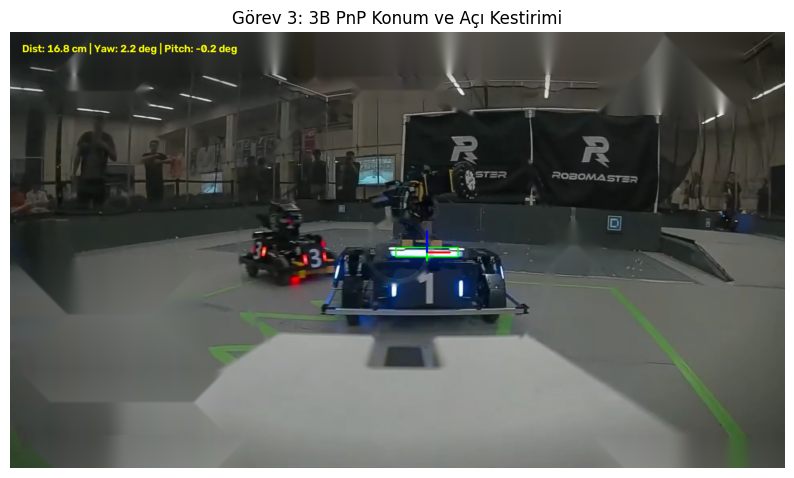

In [14]:
import matplotlib.pyplot as plt

# ==========================================
# GÖREV 3: YAW/PITCH AÇILARI VE 3B EKSEN GÖRSELLEŞTİRME
# ==========================================

# tx, ty, tz değerlerini kullanarak yatay (Yaw) ve dikey (Pitch) sapma açılarını
# derece cinsinden hesaplayın.
# Formüller: Yaw = arctan2(tx, tz), Pitch = arctan2(-ty, tz)
yaw_deg = np.degrees(np.arctan2(tx, tz))
pitch_deg = np.degrees(np.arctan2(-ty,tz))

print(f"Yaw (Yatay Sapma): {yaw_deg:.2f} derece")
print(f"Pitch (Dikey Sapma): {pitch_deg:.2f} derece")

vis_img = img_bgr.copy()

pts_int = image_points.astype(int)
cv2.polylines(vis_img, [pts_int], isClosed=True, color=(0, 255, 0), thickness=2)

# cv2.drawFrameAxes fonksiyonunu kullanarak hedefin merkezine 3B eksenleri (X, Y, Z) çizin.
# length değerini 50.0 (50 mm eksen uzunluğu) olarak verebilirsiniz.
cv2.drawFrameAxes(
    vis_img,
    camera_matrix,
    dist_coeffs,
    rvec,
    tvec,
    length=50.0,
    thickness=3
)

# Hesaplanan mesafe (distance_cm), Yaw ve Pitch değerlerini görüntü üzerine yazdırın.
info_text = f"Dist: {distance_cm:.1f} cm | Yaw: {yaw_deg:.1f} deg | Pitch: {pitch_deg:.1f} deg"
cv2.putText(
    vis_img,
    info_text,
    (30, 50),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.9,
    (0, 255, 255),
    2
)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(vis_img, cv2.COLOR_BGR2RGB))
plt.title("Görev 3: 3B PnP Konum ve Açı Kestirimi")
plt.axis("off")
plt.show()